# RabTech Academy Internship — Task 4

## Supervised Classification Modeling & Hyperparameter Tuning

### Project: Telco Customer Churn Prediction

**Objective:**  
Train and compare multiple supervised classification algorithms,
perform hyperparameter optimization using Stratified K-Fold Cross-Validation,
evaluate models using Precision, Recall, F1-Score, ROC-AUC and Confusion Matrix,
and select a champion model based on validation performance.

### Models Used

1. Logistic Regression
2. Random Forest Classifier
3. Gradient Boosting Classifier
4. XGBoost Classifier

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

os.makedirs("../outputs", exist_ok=True)
os.makedirs("../models", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = "../data/telco_customer_churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Information")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information
Rows: 7043
Columns: 21

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows:
0


In [4]:
print(df["Churn"].value_counts())

print("\nPercentage distribution:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage distribution:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


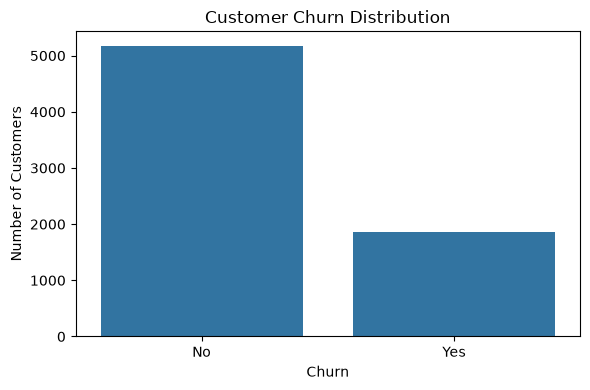

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [7]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [8]:
df = df.drop(columns=["customerID"])

In [9]:
print(df.head())
print(df.shape)

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [10]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (7043, 19)
Target: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 5634
Testing samples: 1409

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [12]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [13]:
numeric_pipeline = Pipeline([
    ("imputer", __import__("sklearn").impute.SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", __import__("sklearn").impute.SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=RANDOM_STATE
    )
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Logistic Regression
- Random Forest
- Gradient Boosting
- XGBoost


In [15]:
param_grids = {
    
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__solver": ["liblinear"],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5],
        "model__class_weight": [None, "balanced"]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__subsample": [0.8, 1.0]
    },

    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0]
    }
}

In [16]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation strategy:")
print(cv)

Cross-validation strategy:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [17]:
grid_results = {}
best_models = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print(f"Training: {name}")
    print("=" * 70)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    grid_results[name] = grid_search
    best_models[name] = grid_search.best_estimator_

    print("\nBest Parameters:")
    print(grid_search.best_params_)

    print("\nBest Cross-Validation ROC-AUC:")
    print(round(grid_search.best_score_, 4))


Training: Logistic Regression
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best Parameters:
{'model__C': 10, 'model__class_weight': None, 'model__solver': 'liblinear'}

Best Cross-Validation ROC-AUC:
0.8463

Training: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.8435

Training: Gradient Boosting
Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best Parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}

Best Cross-Validation ROC-AUC:
0.8508

Training: XGBoost
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Best Parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 0.8}

Best Cross-Validatio

In [18]:
results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.804826,0.673684,0.513369,0.582701,0.847388
1,Gradient Boosting,0.803407,0.663300,0.526738,0.587183,0.846669
2,Logistic Regression,0.804826,0.655172,0.558824,0.603175,0.841125
3,Random Forest,0.751597,0.522388,0.748663,0.615385,0.838912


In [19]:
comparison_df.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved.")

Model comparison saved.


In [20]:
best_params = []

for name, grid in grid_results.items():

    best_params.append({
        "Model": name,
        "Best CV ROC-AUC": grid.best_score_,
        "Best Parameters": str(grid.best_params_)
    })

best_params_df = pd.DataFrame(best_params)

display(best_params_df)

,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.846326,"{'model__C': 10, 'model__class_weight': None, ..."
1,Random Forest,0.843471,"{'model__class_weight': 'balanced', 'model__ma..."
2,Gradient Boosting,0.850763,"{'model__learning_rate': 0.05, 'model__max_dep..."
3,XGBoost,0.850327,"{'model__colsample_bytree': 0.8, 'model__learn..."


In [21]:
best_params_df.to_csv(
    "../outputs/best_model_params.csv",
    index=False
)

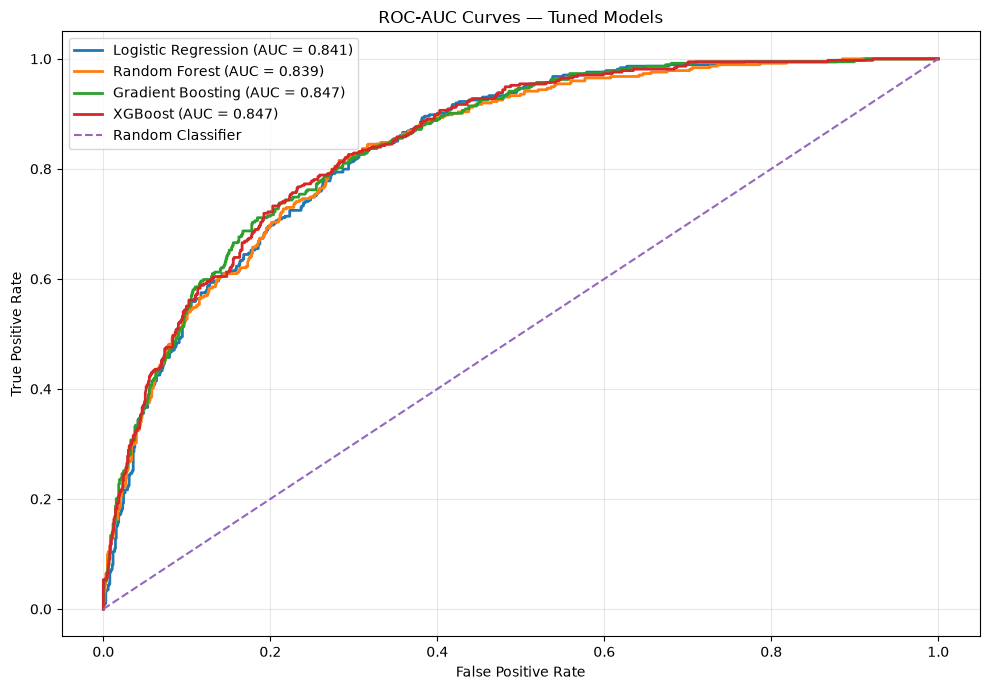

In [22]:
plt.figure(figsize=(10, 7))

for name, model in best_models.items():

    y_proba = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_proba
    )

    auc = roc_auc_score(
        y_test,
        y_proba
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Curves — Tuned Models")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../outputs/roc_auc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
champion_name = comparison_df.iloc[0]["Model"]

champion_model = best_models[champion_name]

print("Champion Model:")
print(champion_name)

print("\nChampion Performance:")
display(
    comparison_df[
        comparison_df["Model"] == champion_name
    ]
)

Champion Model:
XGBoost

Champion Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.804826,0.673684,0.513369,0.582701,0.847388


In [24]:
y_pred_champion = champion_model.predict(X_test)

print("Champion Model:", champion_name)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_champion,
        target_names=["No Churn", "Churn"]
    )
)

Champion Model: XGBoost

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



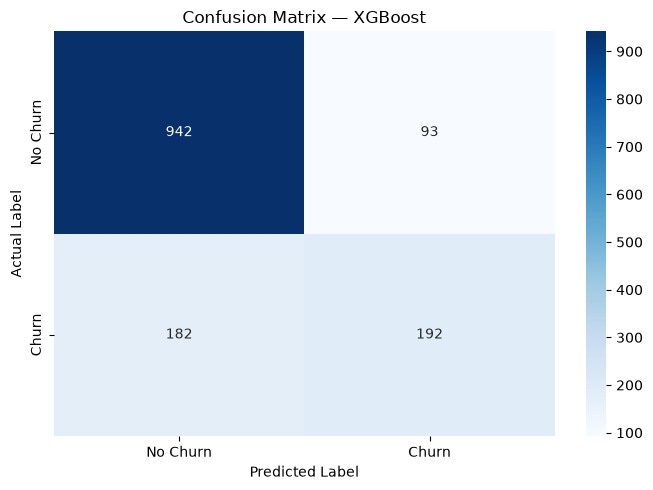

In [25]:
cm = confusion_matrix(
    y_test,
    y_pred_champion
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    f"Confusion Matrix — {champion_name}"
)

plt.tight_layout()

plt.savefig(
    "../outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
MODEL_PATH = "../models/champion_model.pkl"

joblib.dump(
    champion_model,
    MODEL_PATH
)

print("Champion model saved successfully:")
print(MODEL_PATH)

Champion model saved successfully:
../models/champion_model.pkl


In [27]:
import os

print(
    "File exists:",
    os.path.exists(MODEL_PATH)
)

File exists: True


In [28]:
loaded_model = joblib.load(
    MODEL_PATH
)

loaded_predictions = loaded_model.predict(
    X_test
)

print("Serialized model loaded successfully.")

print(
    "Loaded model predictions:",
    loaded_predictions[:10]
)

Serialized model loaded successfully.
Loaded model predictions: [0 1 0 0 0 1 0 0 0 0]


In [29]:
fitted_preprocessor = champion_model.named_steps["preprocessor"]

X_train_processed = fitted_preprocessor.transform(X_train)
X_test_processed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

X_train_processed_df.to_csv(
    "../outputs/X_train_processed.csv"
)

X_test_processed_df.to_csv(
    "../outputs/X_test_processed.csv"
)

y_train.to_csv(
    "../outputs/y_train.csv",
    index=False
)

y_test.to_csv(
    "../outputs/y_test.csv",
    index=False
)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


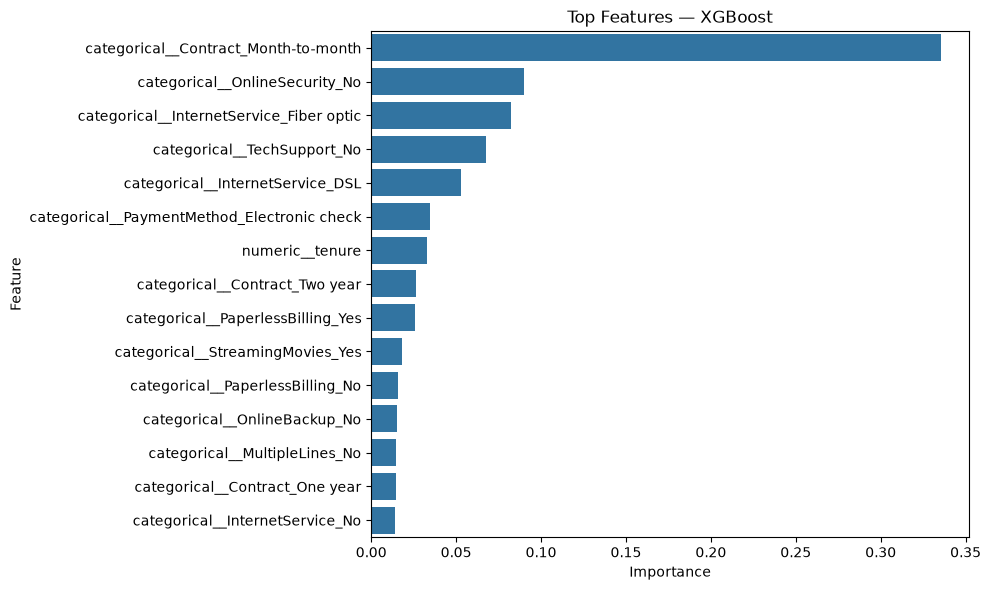

In [30]:
model_step = champion_model.named_steps["model"]

if hasattr(model_step, "feature_importances_"):

    importances = model_step.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title(
        f"Top Features — {champion_name}"
    )

    plt.tight_layout()

    plt.savefig(
        "../outputs/feature_importance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print(
        "Feature importance is not directly available "
        "for this model."
    )

In [31]:
final_metrics = comparison_df.copy()

display(final_metrics)

print("\n" + "=" * 70)
print("FINAL MODEL SELECTION")
print("=" * 70)

print("Champion Model:", champion_name)

champion_row = final_metrics[
    final_metrics["Model"] == champion_name
].iloc[0]

print(f"Accuracy : {champion_row['Accuracy']:.4f}")
print(f"Precision: {champion_row['Precision']:.4f}")
print(f"Recall   : {champion_row['Recall']:.4f}")
print(f"F1-Score : {champion_row['F1-Score']:.4f}")
print(f"ROC-AUC  : {champion_row['ROC-AUC']:.4f}")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.804826,0.673684,0.513369,0.582701,0.847388
1,Gradient Boosting,0.803407,0.663300,0.526738,0.587183,0.846669
2,Logistic Regression,0.804826,0.655172,0.558824,0.603175,0.841125
3,Random Forest,0.751597,0.522388,0.748663,0.615385,0.838912



FINAL MODEL SELECTION
Champion Model: XGBoost
Accuracy : 0.8048
Precision: 0.6737
Recall   : 0.5134
F1-Score : 0.5827
ROC-AUC  : 0.8474


# Conclusion

Four supervised classification algorithms were trained and compared:

1. Logistic Regression
2. Random Forest
3. Gradient Boosting
4. XGBoost

Hyperparameter optimization was performed using GridSearchCV with
5-fold Stratified K-Fold cross-validation.

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix

ROC-AUC was used as the primary validation metric for model selection.

The model achieving the highest validation ROC-AUC was selected as the
champion model.

The final champion model was serialized using Joblib and saved in the
models directory for future deployment and inference.